# 00 · Ingesta y limpieza de datos — PowerShift AI
**Entrada:** `household_data_15min_singleindex.csv` (OPSD Household Data) y `PMLHorarioMDA.csv` (CENACE SIM, PML MDA promedios horarios).
**Salida:** `datos_horarios.csv` y `pml_perfil.csv`, que usan los notebooks 04 y 06.

Decisiones de diseño:
1. **Vivienda:** `DE_KN_residential4`, porque es la única que tiene a la vez `heat_pump`, `ev` y `grid_import`, con más de un año de datos traslapados.
2. **Las columnas de OPSD son lecturas acumuladas de medidor (kWh)**, no energía por intervalo. Se diferencian para obtener kWh por 15 min y se multiplican por 4 para obtener kW.
3. **Hora local:** se convierte de UTC a `Europe/Berlin`. Se descartan los días que no tienen exactamente 96 lecturas: los 3 días de cambio de horario (92 o 100 lecturas) y los 2 días parciales en los extremos de la ventana.
4. **PML:** el archivo contiene un solo día de PML promedio por sistema (SIN, BCA, BCS), no un precio por nodo ni una serie larga. Se usa la columna **SIN** como perfil horario típico de 24 valores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_OPSD = "household_data_15min_singleindex.csv"
CSV_PML = "PMLHorarioMDA.csv"
VIVIENDA = "DE_KN_residential4"
CARGAS = ["grid_import", "heat_pump", "ev"]
TZ_LOCAL = "Europe/Berlin"
MAX_HUECO = 4          # lecturas de 15 min que se interpolan (hasta 1 hora)

## 1. Lectura de OPSD (solo la vivienda elegida)

In [2]:
cols = ["utc_timestamp"] + [f"{VIVIENDA}_{c}" for c in CARGAS]
raw = pd.read_csv(CSV_OPSD, usecols=cols, parse_dates=["utc_timestamp"]).set_index("utc_timestamp")
raw = raw[[f"{VIVIENDA}_{c}" for c in CARGAS]]     # usecols respeta el orden del archivo, no el de la lista
raw.columns = CARGAS
print("Filas:", len(raw), "| Rango UTC:", raw.index.min(), "->", raw.index.max())
print("Lecturas no nulas por columna:")
print(raw.notna().sum())

Filas: 84442 | Rango UTC: 2014-12-11 17:45:00+00:00 -> 2017-05-09 08:00:00+00:00
Lecturas no nulas por columna:
grid_import    55359
heat_pump      49239
ev             55072
dtype: int64


## 2. De lectura acumulada a potencia (kW)
Se verifica que no haya reinicios del medidor (diferencias negativas). Si el medidor es acumulado, `diff()` da los kWh de cada intervalo de 15 min y `kW = kWh / 0.25 h = 4 · kWh`.

In [3]:
dif = raw.diff()
print("Diferencias negativas (reinicios de medidor):")
print((dif < 0).sum())
kw = dif * 4          # kW promedio en cada intervalo de 15 min

# Ventana donde existen las tres columnas
inicio = raw.dropna().index.min()
fin = raw.dropna().index.max()
kw = kw.loc[inicio:fin].copy()
print("Ventana con las 3 cargas:", inicio, "->", fin)

Diferencias negativas (reinicios de medidor):
grid_import    0
heat_pump      0
ev             0
dtype: int64
Ventana con las 3 cargas: 2015-10-13 16:15:00+00:00 -> 2017-03-06 14:00:00+00:00


## 3. Hora local, huecos cortos y días completos

In [4]:
kw.index = kw.index.tz_convert(TZ_LOCAL)
kw = kw.interpolate(method="time", limit=MAX_HUECO)    # solo huecos de hasta 1 h

kw["fecha"] = kw.index.date
n_filas = kw.groupby("fecha").size()
n_nulos = kw[CARGAS].isna().groupby(kw["fecha"]).sum().sum(axis=1)

dias_ok = n_filas[(n_filas == 96) & (n_nulos == 0)].index
print("Días en la ventana:", len(n_filas))
print("Días descartados por no tener 96 lecturas (3 cambios de horario + 2 días parciales en los extremos):", int((n_filas != 96).sum()))
print("Días con huecos largos, descartados:", int(((n_filas == 96) & (n_nulos > 0)).sum()))
print("Días completos conservados:", len(dias_ok))

Días en la ventana: 511
Días descartados por no tener 96 lecturas (3 cambios de horario + 2 días parciales en los extremos): 5
Días con huecos largos, descartados: 0
Días completos conservados: 506


## 4. Promedio horario y cruce con el PML

In [5]:
kw = kw[kw["fecha"].isin(dias_ok)].drop(columns="fecha")
horario = kw.resample("h").mean().dropna()      # kW promedio en la hora = kWh de esa hora
horario.index = horario.index.tz_localize(None)  # hora local de pared
horario["fecha"] = horario.index.date.astype(str)
horario["hora"] = horario.index.hour

# --- PML (CENACE): 4 líneas de encabezado, luego HORA, SIN, BCA, BCS
pml = pd.read_csv(CSV_PML, skiprows=4, skipinitialspace=True)
pml.columns = [c.strip() for c in pml.columns]
pml = pml.dropna(subset=["HORA"])
pml["hora"] = pml["HORA"].astype(int) - 1            # CENACE usa horas 1..24 -> 0..23
pml = pml.rename(columns={"SIN": "pml_sin"})[["hora", "pml_sin"]].reset_index(drop=True)
assert len(pml) == 24 and sorted(pml["hora"]) == list(range(24))
print(pml.T)

# Costo = kW · h · PML / 1000   (PML en MXN/MWh)
horario["pml_sin"] = horario["hora"].map(pml.set_index("hora")["pml_sin"])
for c in ["grid_import", "heat_pump", "ev"]:
    horario[f"costo_{c}"] = horario[c] * 1.0 * horario["pml_sin"] / 1000.0

horario.to_csv("datos_horarios.csv")
pml.to_csv("pml_perfil.csv", index=False)
print("Guardado datos_horarios.csv:", horario.shape, "| días:", horario["fecha"].nunique())
print(horario[["grid_import", "heat_pump", "ev"]].describe().round(3))

             0       1       2       3       4       5       6       7   \
hora       0.00    1.00    2.00    3.00    4.00    5.00    6.00    7.00   
pml_sin  459.23  384.77  363.34  357.08  355.16  365.88  392.16  371.47   

            8       9   ...       14      15      16      17       18  \
hora       8.0    9.00  ...    14.00    15.0   16.00   17.00    18.00   
pml_sin  363.0  359.09  ...  1027.52  1065.9  507.54  784.95  2205.46   

              19       20       21      22     23  
hora       19.00    20.00    21.00   22.00   23.0  
pml_sin  2210.92  2156.31  1216.72  729.29  534.3  

[2 rows x 24 columns]
Guardado datos_horarios.csv: (12144, 9) | días: 506
       grid_import  heat_pump         ev
count    12144.000  12144.000  12144.000
mean         0.555      0.387      0.116
std          0.578      0.436      0.418
min          0.000      0.000      0.000
25%          0.134      0.000      0.000
50%          0.370      0.355      0.000
75%          0.842      0.630      0

## 5. Telemetría limpia de 15 min para la base de datos
Se exportan los mismos 506 días completos, pero a 15 min y en UTC, con las 5 columnas que se cargan en `telemetria_consumo` (`grid_import`, `grid_export`, `pv`, `heat_pump`, `ev`). El pipeline por hora de arriba no se modifica. `grid_export` y `pv` no se usan para filtrar días; si tienen huecos largos quedan como NULL.

In [6]:
EXTRAS = ["grid_export", "pv"]
cols5 = [f"{VIVIENDA}_{c}" for c in CARGAS + EXTRAS]
raw5 = pd.read_csv(CSV_OPSD, usecols=["utc_timestamp"] + cols5, parse_dates=["utc_timestamp"]).set_index("utc_timestamp")
raw5 = raw5[cols5]
raw5.columns = CARGAS + EXTRAS
kw5 = (raw5.diff() * 4).loc[inicio:fin]                 # kW por intervalo de 15 min
kw5.index = kw5.index.tz_convert(TZ_LOCAL)
kw5 = kw5.interpolate(method="time", limit=MAX_HUECO)    # mismo tratamiento que el pipeline principal
kw5 = kw5[pd.Index(kw5.index.date).isin(dias_ok)]        # solo los días completos
kw5.index = kw5.index.tz_convert("UTC")
kw5.index.name = "ts"
tele = kw5.rename(columns={c: f"{c}_kw" for c in CARGAS + EXTRAS}).reset_index()
tele.insert(1, "id_vivienda", VIVIENDA)
tele.to_csv("telemetria_15min.csv", index=False)
print("telemetria_15min.csv:", tele.shape, "| nulos por columna:")
print(tele.isna().sum())

telemetria_15min.csv: (48576, 7) | nulos por columna:
ts                0
id_vivienda       0
grid_import_kw    0
heat_pump_kw      0
ev_kw             0
grid_export_kw    0
pv_kw             0
dtype: int64


## 6. Figura del perfil de PML (SIN)

PML máximo: 2210.92 MXN/MWh en la hora 19


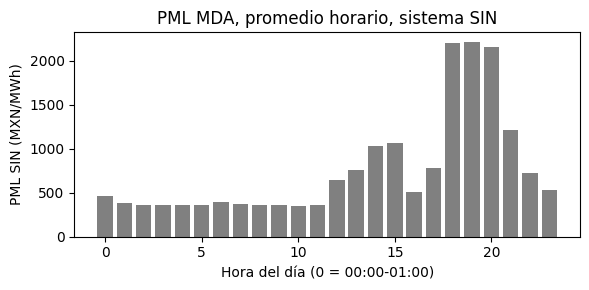

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(pml["hora"], pml["pml_sin"], color="0.5")
ax.set_xlabel("Hora del día (0 = 00:00-01:00)")
ax.set_ylabel("PML SIN (MXN/MWh)")
ax.set_title("PML MDA, promedio horario, sistema SIN")
imax = pml["pml_sin"].idxmax()
print("PML máximo:", pml.loc[imax, "pml_sin"], "MXN/MWh en la hora", pml.loc[imax, "hora"])
fig.tight_layout()
fig.savefig("fig_pml_perfil.pdf"); fig.savefig("fig_pml_perfil.png", dpi=150)